# Project: <your topic here>
> Data Mining · SGH Warsaw School of Economics (223121-0090)

| | |
|---|---|
| **Team** | *Jagger Onstott · Connor Richardson · Youssef Rbahi* |
| **Dataset** | *Hotel Booking Demand + https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand* |

**How to use this template.** Each numbered section matches one criterion of
the project rubric; the percentage in its heading is its weight. Replace every
*TODO* with your own work and keep the section order. If a step does not apply
to your data, say why in one sentence instead of deleting it.

**Rules**
1. *Kernel → Restart & Run All* must run without errors before you upload.
2. The notebook you upload before Block 7 is final.
3. AI assistants are not recommended, but allowed. You answer for every line:
   submissions are read for signs of unchecked generation, and work you cannot
   explain counts as work you did not do.

In [1]:
# Setup: keep this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.max_columns", 50)

SEED = 42  # use this seed everywhere
np.random.seed(SEED)

## 1. Business framing and problem definition (10%)

Describe the business problem and your research question (hypothesis), with a
short literature background. Cover:

- **Decision:** who acts on the model's output, and what they do differently.
- **Unit of analysis:** what one row is.
- **Target:** how it is defined, and when it becomes known relative to the moment of prediction.
- **Cost of errors:** what a false positive and a false negative cost (rough ratios are enough; Section 5 uses them).
- **Success criterion:** what result would justify using the model.

**Business problem.** Hotels lose revenue when a guest cancels and the room stays empty. Many hotels overbook to compensate, but overbooking too far means turning away guests who show up, which costs money and reputation. Deposits and reconfirmation requests are other tools, and all of them work better if the hotel knows which bookings are likely to be cancelled.

**Research question and hypothesis.** Can booking characteristics known around the time of reservation predict cancellation well enough to support these decisions? We expect lead time, deposit type, market segment and previous cancellations to be the strongest predictors, and we expect a gradient boosting model to outperform logistic regression because cancellation behavior likely involves interactions and non-linear effects.

**Literature background.** The data come from Antonio, Almeida and Nunes (2019), "Hotel booking demand datasets", *Data in Brief*, which describes real bookings from a resort hotel and a city hotel in Portugal. The same authors studied cancellation prediction in earlier work (2017, *Tourism & Management Studies*) and report that booking-level features can predict cancellations reasonably well. Cancellation forecasting is also a standard input to revenue management and overbooking policy.

**Decision.** A hotel revenue manager decides, at booking time, which reservations to treat as high cancellation risk. Flagged bookings get a deposit or reconfirmation request, and their predicted risk feeds into the overbooking level for that date.

**Unit of analysis.** One row is one hotel booking (resort or city hotel, arrivals July 2015 to August 2017).

**Target.** `is_canceled` (1 = cancelled, 0 = guest stayed). The outcome is only known on or before the arrival date, so every feature must be available at or shortly after booking. Columns that reveal the outcome, such as `reservation_status` and `reservation_status_date`, are excluded. Columns that can change after booking, such as `assigned_room_type`, `booking_changes` and `days_in_waiting_list`, are checked in the leakage audit in Section 3.

**Cost of errors.** A false negative is a cancellation we missed. The room goes empty, which we assume costs about one night of revenue. A false positive is a guest flagged as risky who would have come. Asking for a deposit may lose the booking or hurt goodwill, which we assume costs about one third of a night. That gives a cost ratio of roughly 3:1. With these costs, flagging a booking is worthwhile when its predicted cancellation probability is above 1 / (1 + 3) = 0.25, so Section 5 will use a threshold near 0.25 instead of 0.5. We will also test how sensitive the result is to other ratios.

**Success criterion.** The flexible model should beat logistic regression on PR-AUC by more than the cross-validation standard deviation and lower the expected cost per booking at the chosen threshold. Its predicted probabilities should also be reasonably well calibrated, since the cost-based threshold depends on them.

## 2. Data understanding (EDA)

Source and description of the data, descriptive statistics, the distribution
of the target, and missing values: how many, where, and why. This section
counts towards the criterion of Section 3.

In [20]:
# TODO: load the data

# Load the raw booking data (the CSV sits in the same folder as the notebook)
df = pd.read_csv("hotel_bookings.csv")

# Size check. These two numbers go into the topic description
print("Rows, columns:", df.shape)
print()

# Column names, data types and non-null counts
df.info()
print()

Rows, columns: (119390, 32)

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12

In [15]:
# TODO: descriptive statistics, distributions, relationships with the target, missing values

# Target balance, missingness, duplicates

# Class balance of the target (1 = cancelled)
print(df["is_canceled"].value_counts())
print()
print(df["is_canceled"].value_counts(normalize=True).round(3))
print()

# Missing values, only for columns that have any
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(pd.DataFrame({"missing": missing, "share": (missing / len(df)).round(4)}))
print()

# Exact duplicate rows (this dataset has a lot, which matters for the train/test split)
print("Duplicate rows:", df.duplicated().sum())

is_canceled
0    75166
1    44224
Name: count, dtype: int64

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64

          missing   share
company    112593  0.9431
agent       16340  0.1369
country       488  0.0041
children        4  0.0000

Duplicate rows: 31994


In [21]:
# Evidence for the leakage audit and the missingness mechanism

# reservation_status is the outcome in another form, so it cannot be a feature
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))
print()

# Is "missing agent" related to cancellation? Helps decide MCAR vs structural missingness
print(df.groupby(df["agent"].isna())["is_canceled"].mean().round(3))
print()
print(df.groupby(df["company"].isna())["is_canceled"].mean().round(3))
print()

# Cancellation rate by deposit type (look closely at "Non Refund", it looks odd)
print(df.groupby("deposit_type")["is_canceled"].agg(["mean", "count"]).round(3))

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207

agent
False    0.390
True     0.247
Name: is_canceled, dtype: float64

company
False    0.175
True     0.382
Name: is_canceled, dtype: float64

               mean   count
deposit_type               
No Deposit    0.284  104641
Non Refund    0.994   14587
Refundable    0.222     162


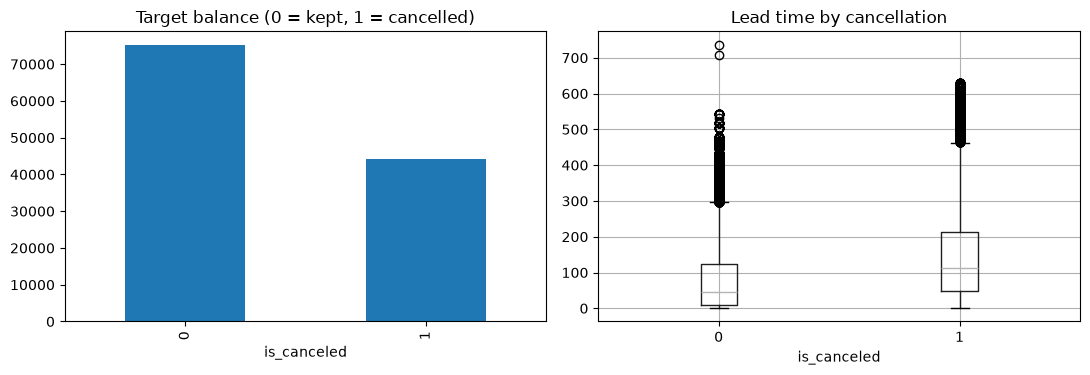

In [23]:
# First plot

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Target balance
df["is_canceled"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Target balance (0 = kept, 1 = cancelled)")

# Lead time by outcome, a likely strong predictor
df.boxplot(column="lead_time", by="is_canceled", ax=axes[1])
axes[1].set_title("Lead time by cancellation")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Data-quality risks:** your top three, and how you will handle each.

1. Duplicate rows. 31,994 rows (26.8%) are exact duplicates. If copies land in both train and test, test scores look better than they are. We will drop duplicates before splitting and report the effect on the cancellation rate.

2. Structural missingness in agent and company. Missing agent and company values are linked to cancellation (24.7% vs 39.0% for agent, 38.2% vs 17.5% for company), so they are not random. They most likely mean “no agent” or “no company”. We will add missing-indicator flags and fill with a constant instead of the mean. country and children have almost no missing values, so a simple fill is fine.

3. Leakage and suspicious columns. reservation_status perfectly reproduces the target and will be dropped along with reservation_status_date. The Non Refund deposit type shows a 99.4% cancellation rate, which looks like a data artifact. We will keep it in the audit and check how much the model depends on it.

## 3. Data preparation and missing values (15%)

Split the data before any transformation, and fit every transformation
(imputation, scaling, encoding) on the training set only, inside a `Pipeline`
where possible.

In [6]:
# TODO: build X and y, then a stratified train/test split with SEED.
# Keep the test set aside until Section 5.

In [7]:
# TODO: preparation steps, including how you handle missing values

**Leakage audit:** for every feature, is its value known at the moment of
prediction? List the features you dropped, and why.

| Feature | Known at prediction time? | Kept / dropped |
|---|---|---|
| *TODO* | | |

## 4. Modelling: at least two model families (15%)

Model I is a simple, transparent baseline, such as logistic regression. Model II
is a more flexible family that has to beat it. Justify both choices and your
tuning.

In [8]:
# TODO: Model I (the baseline), fitted on the training set

# TODO: Model II (a more flexible family), compared with Model I on the same split

## 5. Evaluation: correct and leakage-aware (20%)

Evaluate both models on data they have not seen, with metrics that fit your
problem: cross-validation on the training set, then one check on the test set.
Choose the operating threshold from the error costs in Section 1.

In [9]:
# TODO: evaluation

**Conclusion:** which model is better, by how much, and at which threshold would
you use it?

*TODO*

## 6. Interpretation and recommendation (15%)

Explain what drives the predictions, check that the directions agree with your
EDA, and turn the results into a recommendation for the decision-maker from
Section 1.

In [10]:
# TODO: what drives the predictions of each model

- **Interpretation:** *TODO*
- **Recommendation:** *TODO*
- **Limitations:** *TODO*

## 7. Reproducibility (5%)

Before the upload (before Block 7, 17:10):

- [ ] *Kernel → Restart & Run All* runs without errors, ideally on a teammate's computer
- [ ] every number you report is computed in this notebook
- [ ] the data file is included or downloaded by the code; paths are relative
- [ ] seeds are fixed, and a re-run gives identical results